In [1]:
import sys

print(sys.version)
print(sys.executable)

3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)]
d:\Academics\TrustLens\.venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Dataset location
DATA_DIR =Path("../data/raw")

# Load Dataset
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
test_labels_df = pd.read_csv(DATA_DIR / "test_labels.csv")

print("Datasets Loaded Successfully")

Datasets Loaded Successfully


In [4]:
print("TRAIN DATASET")
print("Shape:", train_df.shape)

print("\nTEST DATASET")
print("Shape:",test_df.shape)

print("\nTEST LABELS DATASET")
print("Shape:",test_labels_df.shape)

TRAIN DATASET
Shape: (159571, 8)

TEST DATASET
Shape: (153164, 2)

TEST LABELS DATASET
Shape: (153164, 7)


In [5]:
print("Training  columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nTest Label Columns:")
print(test_labels_df.columns.tolist())

Training  columns:
['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Test columns:
['id', 'comment_text']

Test Label Columns:
['id', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [6]:
display(train_df.head(10))

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0


In [8]:
for i in range(5):
    print(f"\nComment {i+1}:")
    print(train_df.loc[i, "comment_text"])


Comment 1:
Explanation
Why the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27

Comment 2:
D'aww! He matches this background colour I'm seemingly stuck with. Thanks.  (talk) 21:51, January 11, 2016 (UTC)

Comment 3:
Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits instead of my talk page. He seems to care more about the formatting than the actual info.

Comment 4:
"
More
I can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of ""types of accidents""  -I think the references may need tidying so that they are all in the exact same format ie date format etc. I can do that later on, if no-one else does first - if you have any prefere

In [9]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 72.2 MB


In [10]:
print("Missing values:")
display(train_df.isnull().sum())

Missing values:


id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [11]:
print("Duplicate rows:", train_df.duplicated().sum())

print("Duplicate comments:", train_df["comment_text"].duplicated().sum())

Duplicate rows: 0
Duplicate comments: 0


In [12]:
label_columns=[
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

label_counts = train_df[label_columns].sum().sort_values(ascending=False)

display(label_counts)

toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64

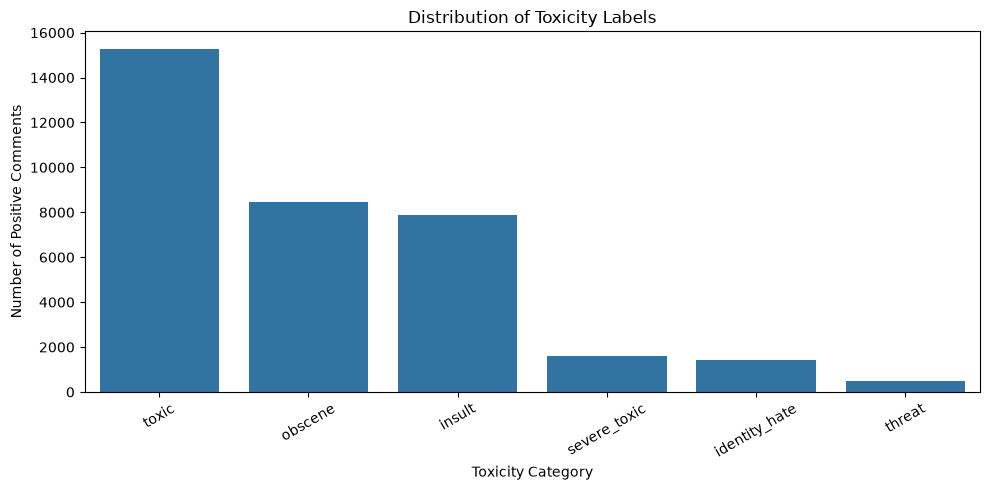

In [14]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("Distribution of Toxicity Labels")
plt.xlabel("Toxicity Category")
plt.ylabel("Number of Positive Comments")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [16]:
print("Test label distribution:")

display(
    test_labels_df[label_columns].apply(
        pd.Series.value_counts
    )
)

Test label distribution:


,toxic,severe_toxic,obscene,threat,insult,identity_hate
-1,89186,89186,89186,89186,89186,89186
0,57888,63611,60287,63767,60551,63266
1,6090,367,3691,211,3427,712


In [19]:
# 1. Dataset dimensions
print("========== DATASET DIMENSIONS ==========")
print("Training:", train_df.shape)
print("Testing:", test_df.shape)
print("Test labels:", test_labels_df.shape)


# 2. Column information
print("\n========== COLUMN INFORMATION ==========")
print("Training columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())


# 3. Missing values
print("\n========== MISSING VALUES ==========")
print(train_df.isnull().sum())


# 4. Duplicate records
print("\n========== DUPLICATES ==========")
print("Duplicate rows:", train_df.duplicated().sum())
print("Duplicate comments:", train_df["comment_text"].duplicated().sum())


# 5. Label distribution
label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print("\n========== LABEL DISTRIBUTION ==========")
print(train_df[label_columns].sum())


# 6. Test label values
print("\n========== TEST LABEL DISTRIBUTION ==========")
print(test_labels_df[label_columns].apply(
    lambda col: col.value_counts().sort_index()
))



========== DATASET DIMENSIONS ==========
Training: (159571, 8)
Testing: (153164, 2)
Test labels: (153164, 7)

========== COLUMN INFORMATION ==========
Training columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
Test columns: ['id', 'comment_text']

========== MISSING VALUES ==========
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

========== DUPLICATES ==========
Duplicate rows: 0
Duplicate comments: 0

========== LABEL DISTRIBUTION ==========
toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64

========== TEST LABEL DISTRIBUTION ==========
    toxic  severe_toxic  obscene  threat  insult  identity_hate
-1  89186         89186    89186   89186   89186          89186
 0  57888         63611    60287   63767   60551     

In [20]:
label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

label_summary = pd.DataFrame({
    "Positive_Count": train_df[label_columns].sum(),
    "Negative_Count": (train_df[label_columns] == 0).sum(),
    "Positive_Percentage": train_df[label_columns].mean() * 100
})

display(label_summary.round(2))

,Positive_Count,Negative_Count,Positive_Percentage
toxic,15294,144277,9.58
severe_toxic,1595,157976,1.00
obscene,8449,151122,5.29
threat,478,159093,0.30
insult,7877,151694,4.94
identity_hate,1405,158166,0.88


In [21]:
# Calculate comment lengths
train_df['comment_length']= train_df['comment_text'].str.len()

print('Comment length statistics:')
display(train_df['comment_length'].describe())

Comment length statistics:


count    159571.000000
mean        394.073221
std         590.720282
min           6.000000
25%          96.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: comment_length, dtype: float64

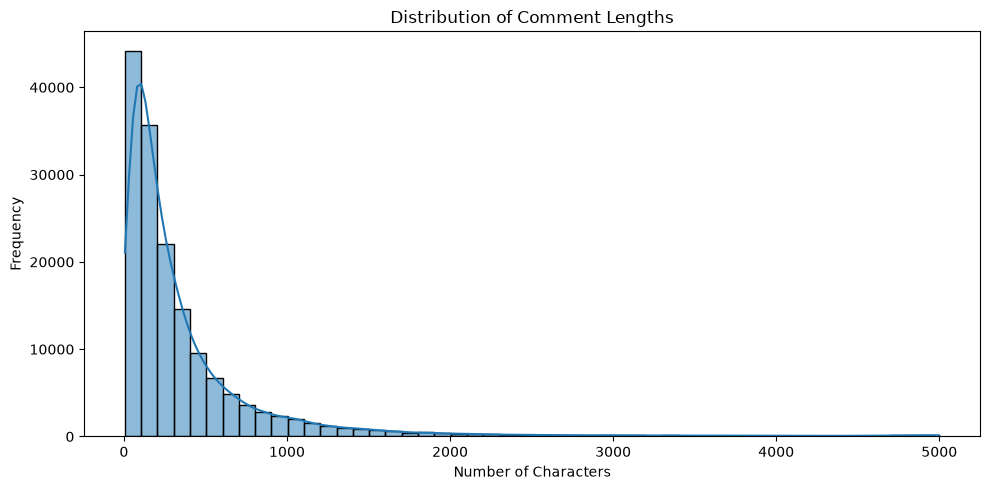

In [23]:
plt.figure(figsize=(10,5))

sns.histplot(
    train_df['comment_length'],
    bins=50,
    kde=True,
)

plt.title('Distribution of Comment Lengths')
plt.xlabel("Number of Characters")
plt.ylabel("Frequency") 

plt.tight_layout()
plt.show()


In [24]:
train_df['word_count'] = train_df['comment_text'].str.split().str.len()

display(train_df['word_count'].describe())

count    159571.000000
mean         67.273527
std          99.230702
min           1.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: word_count, dtype: float64

In [25]:
# Character and word length analysis

train_df["character_count"] = train_df["comment_text"].str.len()

train_df["word_count"] = (
    train_df["comment_text"].str.split().str.len()
)

print("Character count percentiles:")
display(train_df["character_count"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
))

print("\nWord count percentiles:")
display(train_df["word_count"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
))

Character count percentiles:


0.50     205.0
0.75     435.0
0.90     889.0
0.95    1355.0
0.99    3444.0
1.00    5000.0
Name: character_count, dtype: float64


Word count percentiles:


0.50      36.0
0.75      75.0
0.90     152.0
0.95     230.0
0.99     567.0
1.00    1411.0
Name: word_count, dtype: float64

In [26]:
thresholds = [100, 200, 300, 500, 1000]

for threshold in thresholds:
    count = (train_df["word_count"] > threshold).sum()

    percentage = count / len(train_df) * 100

    print(
        f"Comments above {threshold} words: "
        f"{count:,} ({percentage:.2f}%)"
    )

Comments above 100 words: 28,199 (17.67%)
Comments above 200 words: 10,087 (6.32%)
Comments above 300 words: 4,823 (3.02%)
Comments above 500 words: 2,066 (1.29%)
Comments above 1000 words: 31 (0.02%)


In [27]:
label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

label_summary = pd.DataFrame({
    "Positive_Count": train_df[label_columns].sum(),
    "Negative_Count": (train_df[label_columns] == 0).sum(),
    "Positive_Percentage": train_df[label_columns].mean() * 100
})

display(label_summary.round(2))

,Positive_Count,Negative_Count,Positive_Percentage
toxic,15294,144277,9.58
severe_toxic,1595,157976,1.00
obscene,8449,151122,5.29
threat,478,159093,0.30
insult,7877,151694,4.94
identity_hate,1405,158166,0.88


In [28]:
label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

cooccurrence = train_df[label_columns].T.dot(
    train_df[label_columns]
)

display(cooccurrence)

,toxic,severe_toxic,obscene,threat,insult,identity_hate
toxic,15294,1595,7926,449,7344,1302
severe_toxic,1595,1595,1517,112,1371,313
obscene,7926,1517,8449,301,6155,1032
threat,449,112,301,478,307,98
insult,7344,1371,6155,307,7877,1160
identity_hate,1302,313,1032,98,1160,1405


In [29]:
train_df["label_count"] = train_df[label_columns].sum(axis=1)

print("Number of labels per comment:")
display(train_df["label_count"].value_counts().sort_index())

Number of labels per comment:


label_count
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64

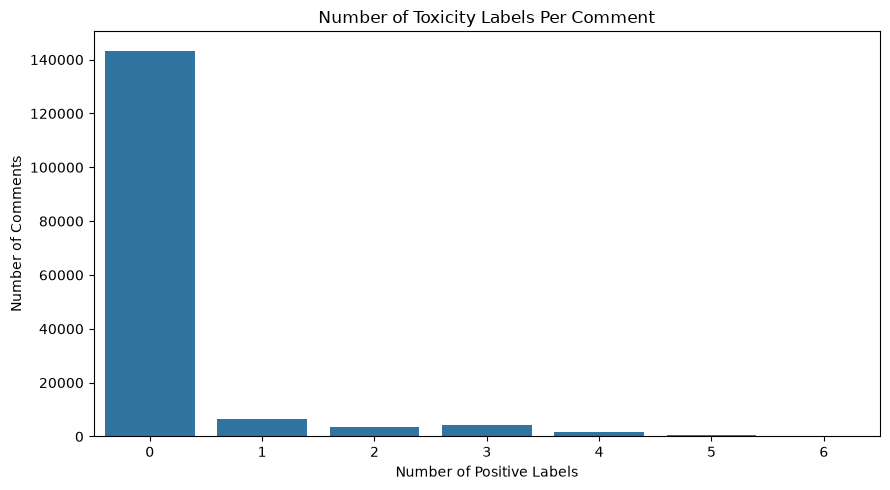

In [30]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_df,
    x="label_count"
)

plt.title("Number of Toxicity Labels Per Comment")
plt.xlabel("Number of Positive Labels")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.show()

In [31]:
multi_label_comments = train_df[
    train_df["label_count"] >= 2
]

display(
    multi_label_comments[
        ["comment_text"] + label_columns
    ].head(10)
)

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
42,You are gay or antisemmitian? \n\nArchangel WH...,1,0,1,0,1,1
43,"FUCK YOUR FILTHY MOTHER IN THE ASS, DRY!",1,0,1,0,1,0
51,GET FUCKED UP. GET FUCKEEED UP. GOT A DRINK T...,1,0,1,0,0,0
55,Stupid peace of shit stop deleting my stuff as...,1,1,1,0,1,0
56,=Tony Sidaway is obviously a fistfuckee. He lo...,1,0,1,0,1,0
58,My Band Page's deletion. You thought I was gon...,1,0,1,0,0,0
65,All of my edits are good. Cunts like you who ...,1,0,1,0,1,0
79,Hi! I am back again!\nLast warning!\nStop undo...,1,0,0,1,0,0
86,"Would you both shut up, you don't run wikipedi...",1,0,0,0,1,0


In [32]:
sample_comments = train_df["comment_text"].sample(
    15,
    random_state=42
)

for index, comment in sample_comments.items():
    print(f"\nComment {index}:")
    print(comment)
    print("-" * 80)


Comment 119105:
Geez, are you forgetful!  We've already discussed why Marx  was  not an anarchist, i.e. he wanted to use a State to mold his 'socialist man.'  Ergo, he is a statist - the opposite of an  anarchist.  I know a guy who says that, when he gets old and his teeth fall out, he'll quit eating meat.  Would you call him a vegetarian?
--------------------------------------------------------------------------------

Comment 131631:
Carioca RFA 

Thanks for your support on my request for adminship.

The final outcome was (31/4/1), so I am now an administrator. If you have any comments or concerns on my actions as an administrator, please let me know. Thank you!
--------------------------------------------------------------------------------

Comment 125326:
"

 Birthday 

No worries, It's what I do ;)Enjoy ur day|talk|e "
--------------------------------------------------------------------------------

Comment 111256:
Pseudoscience category? 

I'm assuming that this article is in t

In [33]:
sample_comments = train_df['comment_text'].sample(15, random_state=42)

for index,comment in sample_comments.items():
    print(f"\nComment {index}:")
    print(comment)
    print("-" * 80)


Comment 119105:
Geez, are you forgetful!  We've already discussed why Marx  was  not an anarchist, i.e. he wanted to use a State to mold his 'socialist man.'  Ergo, he is a statist - the opposite of an  anarchist.  I know a guy who says that, when he gets old and his teeth fall out, he'll quit eating meat.  Would you call him a vegetarian?
--------------------------------------------------------------------------------

Comment 131631:
Carioca RFA 

Thanks for your support on my request for adminship.

The final outcome was (31/4/1), so I am now an administrator. If you have any comments or concerns on my actions as an administrator, please let me know. Thank you!
--------------------------------------------------------------------------------

Comment 125326:
"

 Birthday 

No worries, It's what I do ;)Enjoy ur day|talk|e "
--------------------------------------------------------------------------------

Comment 111256:
Pseudoscience category? 

I'm assuming that this article is in t

In [34]:
import re

html_entity_pattern = r"&(?:[a-zA-Z]+|#\d+|#x[0-9a-fA-F]+);"

html_entity_count = train_df["comment_text"].str.contains(
    html_entity_pattern,
    regex=True
).sum()

print("Comments containing HTML entities:", html_entity_count)

Comments containing HTML entities: 1182


In [35]:
url_pattern = r"https?://\S+|www\.\S+"

url_count = train_df["comment_text"].str.contains(
    url_pattern,
    case=False,
    regex=True
).sum()

print("Comments containing URLs:", url_count)

Comments containing URLs: 5114


In [36]:
uppercase_comments = train_df['comment_text'].apply(lambda text: text.isupper())

print("Entirely uppercase comments:", uppercase_comments.sum())

Entirely uppercase comments: 1702


In [38]:
train_df['word_count']= (train_df['comment_text'].str.split().str.len())

length_by_toxicity = train_df.groupby('toxic')['word_count'].describe()

display(length_by_toxicity)

,count,mean,std,min,25%,50%,75%,max
toxic,,,,,,,,
0,144277.0,68.967874,98.279574,1.0,18.0,38.0,78.0,1250.0
1,15294.0,51.289787,106.475663,2.0,11.0,22.0,48.0,1411.0


In [42]:
# Inspect variables created during preprocessing and feature engineering

for name in [
    "train_data",
    "validation_data",
    "X_train_tfidf",
    "X_val_tfidf",
    "y_train",
    "y_val",
    "train_labels",
    "validation_labels"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: {type(value)} | shape: {getattr(value, 'shape', 'N/A')}")